# Synthetic Dataset

In [61]:
import pandas as pd

data = {
    "product_interest": [5, 4, 1, 2, 5, 3, 1, 4, 5, 2],
    "website_visits":   [5, 4, 1, 2, 5, 3, 1, 4, 5, 2],
    "time_on_site":     [4, 5, 1, 2, 5, 3, 1, 4, 5, 2],
    "previous_purchases": [3, 2, 0, 1, 4, 1, 0, 2, 5, 0],
    "added_to_cart":    [1, 1, 0, 0, 1, 0, 0, 1, 1, 0],
    "will_buy":         [1, 1, 0, 0, 1, 0, 0, 1, 1, 0]
}

df = pd.DataFrame(data)
df

,product_interest,website_visits,time_on_site,previous_purchases,added_to_cart,will_buy
0,5,5,4,3,1,1
1,4,4,5,2,1,1
2,1,1,1,0,0,0
3,2,2,2,1,0,0
4,5,5,5,4,1,1
5,3,3,3,1,0,0
6,1,1,1,0,0,0
7,4,4,4,2,1,1
8,5,5,5,5,1,1
9,2,2,2,0,0,0


# Load the Dataset

In [62]:
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   product_interest    10 non-null     int64
 1   website_visits      10 non-null     int64
 2   time_on_site        10 non-null     int64
 3   previous_purchases  10 non-null     int64
 4   added_to_cart       10 non-null     int64
 5   will_buy            10 non-null     int64
dtypes: int64(6)
memory usage: 612.0 bytes


,product_interest,website_visits,time_on_site,previous_purchases,added_to_cart,will_buy
count,10.000000,10.000000,10.000000,10.00000,10.000000,10.000000
mean,3.200000,3.200000,3.200000,1.80000,0.500000,0.500000
std,1.619328,1.619328,1.619328,1.75119,0.527046,0.527046
min,1.000000,1.000000,1.000000,0.00000,0.000000,0.000000
25%,2.000000,2.000000,2.000000,0.25000,0.000000,0.000000
50%,3.500000,3.500000,3.500000,1.50000,0.500000,0.500000
75%,4.750000,4.750000,4.750000,2.75000,1.000000,1.000000
max,5.000000,5.000000,5.000000,5.00000,1.000000,1.000000


# Separating the Features from the Ground Truth

In [63]:
X = df[[
    "product_interest",
    "website_visits",
    "time_on_site",
    "previous_purchases",
    "added_to_cart"
]]

y = df["will_buy"]


# # Train/Test Split

In [64]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale the Data

In [65]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Building the Neural Network

In [66]:
import tensorflow as tf
from tensorflow import keras

model = keras.Sequential([
    keras.layers.Dense(16, activation="relu", input_shape=(5,)),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

c:\Users\Carti\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Compile the Model

In [67]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


# Traing the Model

In [68]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=60,
    validation_split=0.2,
    verbose=1
)


Epoch 1/60
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.8333 - loss: 0.6367 - val_accuracy: 0.5000 - val_loss: 0.6068
Epoch 2/60
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.8333 - loss: 0.6284 - val_accuracy: 0.5000 - val_loss: 0.5902
Epoch 3/60
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.8333 - loss: 0.6203 - val_accuracy: 0.5000 - val_loss: 0.5739
Epoch 4/60
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.8333 - loss: 0.6124 - val_accuracy: 0.5000 - val_loss: 0.5586
Epoch 5/60
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.8333 - loss: 0.6049 - val_accuracy: 0.5000 - val_loss: 0.5446
Epoch 6/60
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.8333 - loss: 0.5979 - val_accuracy: 0.5000 - val_loss: 0.5309
Epoch 7/60
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.8333 - loss: 0.5910 - val_accuracy: 0.5000 - val_loss: 0.5176
Epoch 8/60
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.8333 - loss: 0.5843 - val_accuracy: 1.0000 - val_loss: 0.504

# Evaluate the Model

In [69]:
loss, accuracy = model.evaluate(X_test_scaled, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 1.0000 - loss: 0.3847
Test Loss: 0.3847419023513794
Test Accuracy: 1.0


# Make a prediction

In [70]:
new_movie = [[5, 5, 4, 3, 1]]

new_movie_scaled = scaler.transform(new_movie)

prediction = model.predict(new_movie_scaled)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
[[0.6881582]]


c:\Users\Carti\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [71]:
if prediction[0][0] >= 0.5:
    print("Recommend")
else:
    print("Do Not Recommend")

Recommend


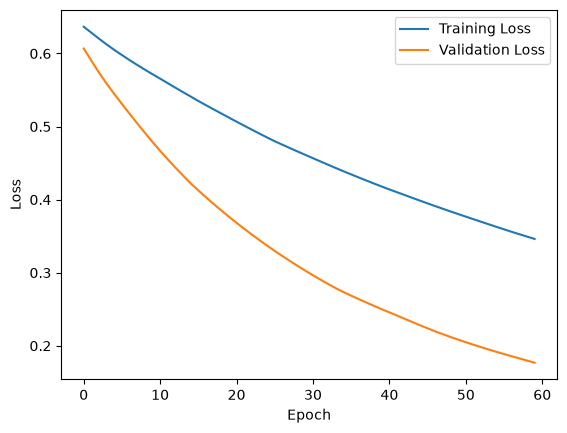

In [72]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()